# Fase 1 · EDA — Home Credit Default Risk

**Pregunta de esta fase:** ¿qué hay que saber de los datos *antes* de escribir una sola feature?

Seis cosas, en este orden: desbalance, nulos, el centinela de `DAYS_EMPLOYED`, el poder de las
`EXT_SOURCE_*`, la forma de la relación con montos y edad, y el sesgo por género, edad y
educación. Cada figura termina con su conclusión escrita.

Todo se lee desde `data/interim/*.parquet` (generado en la fase 0) con DuckDB.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import LogLocator, NullFormatter

from ayni.config import FIGURES_DIR, INTERIM_DIR, TARGET

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 140,
        "font.size": 9,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titlesize": 10,
        "axes.titleweight": "bold",
    }
)
OK, BAD, INK = "#2E6F95", "#C44536", "#333333"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name: str) -> None:
    """Guarda la figura en reports/figures y la muestra."""
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()


def cargar(nombre: str) -> pd.DataFrame:
    return (
        duckdb.connect()
        .execute(f"SELECT * FROM read_parquet('{(INTERIM_DIR / f'{nombre}.parquet').as_posix()}')")
        .df()
    )


app = cargar("application_train")
n_columnas_crudas = app.shape[1]
print(f"{app.shape[0]:,} solicitudes × {app.shape[1]} columnas")

307,511 solicitudes × 122 columnas


## 1 · Desbalance de clases

In [2]:
conteo = app[TARGET].value_counts().sort_index()
tasa = app[TARGET].mean()
print(f"impagos: {conteo[1]:,}    al día: {conteo[0]:,}")
print(f"tasa de impago: {tasa:.2%}")
print(f"ratio mayoritaria:minoria ≈ {conteo[0] / conteo[1]:.1f}:1")

impagos: 24,825    al día: 282,686
tasa de impago: 8.07%
ratio mayoritaria:minoria ≈ 11.4:1


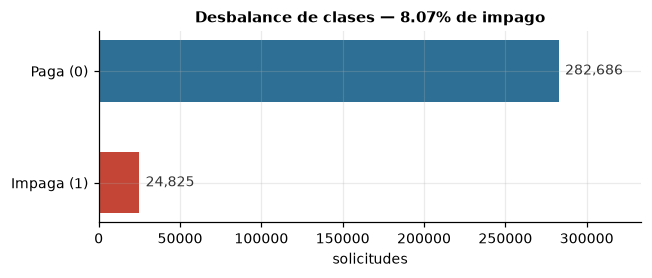

In [3]:
fig, ax = plt.subplots(figsize=(6, 2.6))
barras = ax.barh(["Impaga (1)", "Paga (0)"], [conteo[1], conteo[0]], color=[BAD, OK], height=0.55)
for barra, n in zip(barras, [conteo[1], conteo[0]], strict=True):
    ax.text(n + 4000, barra.get_y() + barra.get_height() / 2, f"{n:,}", va="center", color=INK)
ax.set_xlim(0, conteo[0] * 1.18)
ax.set_title(f"Desbalance de clases — {tasa:.2%} de impago")
ax.set_xlabel("solicitudes")
save(fig, "01_desbalance")

**Conclusión 1.** El 92 % de las solicitudes paga. Un modelo que apruebe a todos acierta el
91.9 % de las veces y es inútil. Por eso esta fase y las siguientes usan **ROC-AUC y PR-AUC**,
nunca accuracy, y el desbalance se trata con `scale_pos_weight`, no con resampling.

## 2 · Nulos por columna

In [4]:
nulos = app.isna().mean().sort_values(ascending=False)
sobre50 = (nulos > 0.5).sum()
sobre30 = (nulos > 0.3).sum()
print(f"columnas con >50 % de nulos: {sobre50} de {len(nulos)}")
print(f"columnas con >30 % de nulos: {sobre30}")
print(f"columnas completas: {(nulos == 0).sum()}")
print("\ntop 10:")
print(nulos.head(10).mul(100).round(1).to_string())

columnas con >50 % de nulos: 41 de 122
columnas con >30 % de nulos: 50
columnas completas: 55

top 10:
COMMONAREA_AVG              69.9
COMMONAREA_MODE             69.9
COMMONAREA_MEDI             69.9
NONLIVINGAPARTMENTS_MEDI    69.4
NONLIVINGAPARTMENTS_MODE    69.4
NONLIVINGAPARTMENTS_AVG     69.4
FONDKAPREMONT_MODE          68.4
LIVINGAPARTMENTS_AVG        68.4
LIVINGAPARTMENTS_MEDI       68.4
LIVINGAPARTMENTS_MODE       68.4


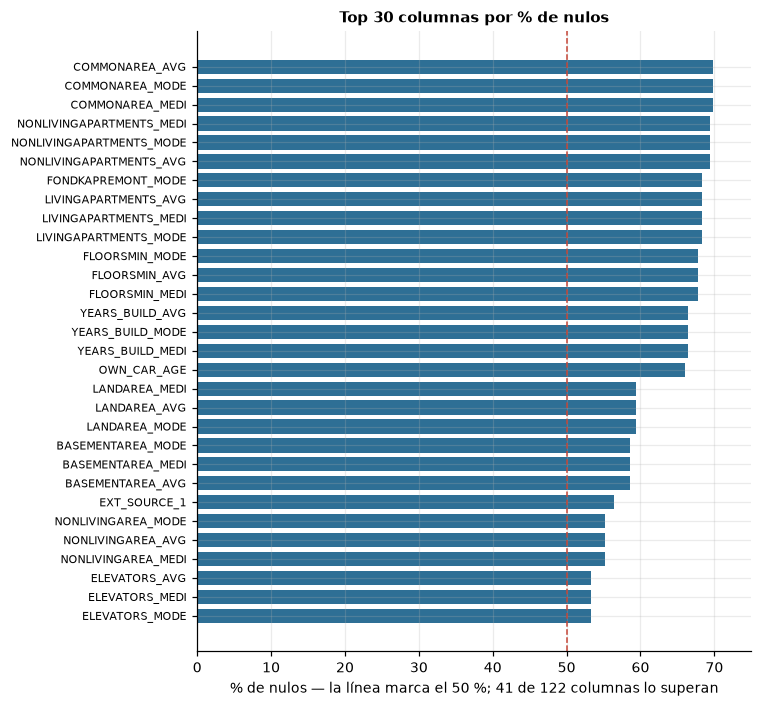

In [5]:
fig, ax = plt.subplots(figsize=(7, 6.5))
top = nulos.head(30)[::-1]
ax.barh(top.index, top.values * 100, color=OK, height=0.75)
ax.axvline(50, color=BAD, ls="--", lw=1)
ax.set_xlabel(f"% de nulos — la línea marca el 50 %; {sobre50} de {len(nulos)} columnas lo superan")
ax.set_xlim(0, 75)
ax.set_title("Top 30 columnas por % de nulos")
ax.tick_params(axis="y", labelsize=7)
save(fig, "02_nulos")

**Conclusión 2.** Un tercio de las columnas de la solicitud (41 de 122) está vacía en más de la
mitad de los casos. No se imputa en bloque: LightGBM trata el nulo como una categoría más, así que
**se dejan como `NaN`** y solo se imputa donde el modelo no lo hace (baseline logístico, fase 4).
Las columnas con >65 % de nulos (`COMMONAREA_*`, `LIVINGAPARTMENTS_*`) son candidatas a
descartarse si no aportan en la fase 4.

## 3 · El centinela `DAYS_EMPLOYED = 365243`

In [6]:
CENTINELA = 365_243
es_centinela = app["DAYS_EMPLOYED"] == CENTINELA
print(f"filas con el centinela: {es_centinela.sum():,} ({es_centinela.mean():.2%})")
print(app.groupby(es_centinela)[TARGET].agg(["size", "mean"]).rename_axis("centinela"))

filas con el centinela: 55,374 (18.01%)
             size      mean
centinela                  
False      252137  0.086600
True        55374  0.053996


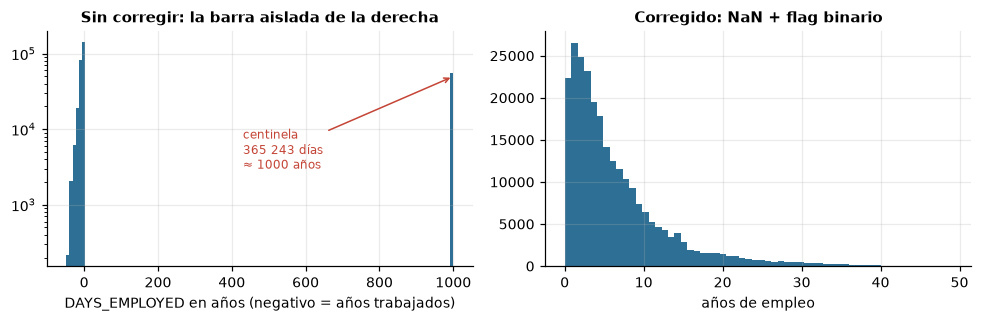

In [7]:
app["empleo_anios"] = np.where(es_centinela, np.nan, -app["DAYS_EMPLOYED"] / 365.25)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.hist(app["DAYS_EMPLOYED"] / 365.25, bins=120, color=OK)
ax1.set_yscale("log")
ax1.set_title("Sin corregir: la barra aislada de la derecha")
ax1.set_xlabel("DAYS_EMPLOYED en años (negativo = años trabajados)")
ax1.annotate(
    "centinela\n365 243 días\n≈ 1000 años",
    xy=(1000, 5e4),
    xytext=(430, 3e3),
    fontsize=8,
    color=BAD,
    ha="left",
    arrowprops={"arrowstyle": "->", "color": BAD},
)
ax2.hist(app["empleo_anios"].dropna(), bins=60, color=OK)
ax2.set_title("Corregido: NaN + flag binario")
ax2.set_xlabel("años de empleo")
save(fig, "03_days_employed")

**Conclusión 3.** 55 374 solicitudes (18.0 % del total) traen `365243`, que no significa "lleva
1000 años en el trabajo" sino que es el código de **jubilado / desempleado**. Si se deja crudo, el
modelo aprende una regla absurda sobre una columna que mide "días". **Decisión:** se reemplaza por
`NaN` y se crea el flag binario `employed_anomaly`, que conserva la información real ("no tiene
empleo formal").
Y el flag no es ruido: ese grupo **impaga menos** (5.4 % vs. 8.7 %), que es exactamente lo que se
espera de alguien con pensión o sin crédito laboral activo. Sin el flag, el `NaN` borraría esa
señal; con la columna cruda, el modelo la usaría en la dirección equivocada.

## 4 · `EXT_SOURCE_*`: las variables que más mueven la aguja

In [8]:
ext = [f"EXT_SOURCE_{i}" for i in (1, 2, 3)]
print("correlación con el impago (negativa = más score, menos riesgo):")
for col in ext:
    print(f"  {col}: {app[col].corr(app[TARGET]):+.3f}   nulos: {app[col].isna().mean():.1%}")

correlación con el impago (negativa = más score, menos riesgo):
  EXT_SOURCE_1: -0.155   nulos: 56.4%
  EXT_SOURCE_2: -0.160   nulos: 0.2%
  EXT_SOURCE_3: -0.179   nulos: 19.8%


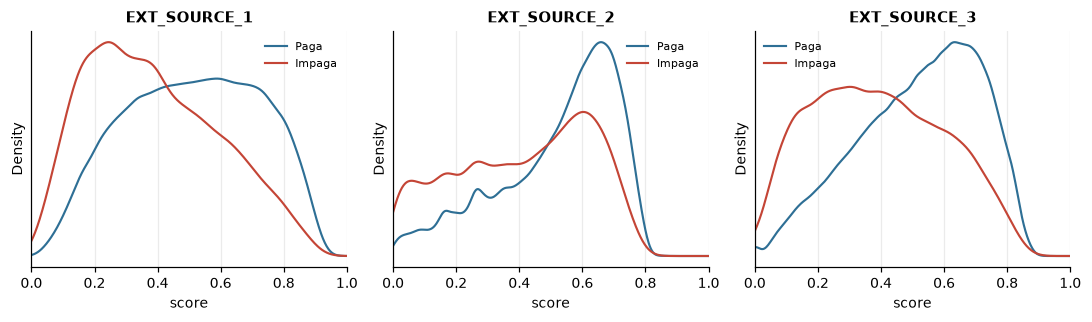

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col in zip(axes, ext, strict=True):
    for valor, etiqueta, color in [(0, "Paga", OK), (1, "Impaga", BAD)]:
        serie = app.loc[app[TARGET] == valor, col].dropna()
        serie.plot(kind="kde", ax=ax, color=color, label=etiqueta, lw=1.4)
    ax.set_title(col)
    ax.set_xlabel("score")
    ax.set_xlim(0, 1)
    ax.set_yticks([])
    ax.legend(frameon=False, fontsize=7)
save(fig, "04_ext_source")

**Conclusión 4.** Las tres `EXT_SOURCE_*` son las variables continuas más informativas del
dataset: a mayor score, menos impago, y las distribuciones de quien paga y quien no están
claramente separadas. Son el núcleo del modelo y, a la vez, **las que hay que explicar con
cuidado** en la fase 6: un score externo es un dato de terceros, no algo que el cliente entienda.

## 5 · Edad, ingresos y monto del crédito

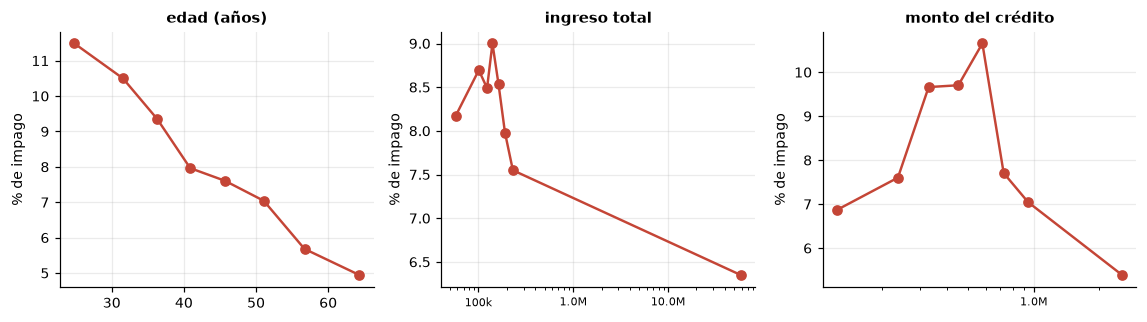

In [10]:
app["edad"] = -app["DAYS_BIRTH"] / 365.25
app["cuota_ingreso"] = app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"]


def tasa_por_corte(serie: pd.Series, q: int = 8) -> pd.Series:
    """Tasa de impago por cuantiles de una variable."""
    grupos = pd.qcut(serie, q=q, duplicates="drop")
    return app.groupby(grupos, observed=True)[TARGET].mean()


paneles = [
    ("edad", "edad (años)", "linear"),
    ("AMT_INCOME_TOTAL", "ingreso total", "log"),
    ("AMT_CREDIT", "monto del crédito", "log"),
]
moneda = plt.FuncFormatter(lambda x, _: f"{x / 1e3:,.0f}k" if x < 1e6 else f"{x / 1e6:,.1f}M")

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3))
for ax, (col, etiqueta, escala) in zip(axes, paneles, strict=True):
    serie = tasa_por_corte(app[col])
    centros = [intervalo.mid for intervalo in serie.index]
    ax.plot(centros, serie.values * 100, marker="o", color=BAD, lw=1.6)
    ax.set_xscale(escala)
    ax.set_title(etiqueta)
    ax.set_ylabel("% de impago")
    if escala == "log":
        ax.xaxis.set_major_locator(LogLocator(base=10, numticks=4))
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.xaxis.set_major_formatter(moneda)
        ax.tick_params(axis="x", labelsize=7)
save(fig, "05_cortes_numericos")

**Conclusión 5.** La edad es el patrón más limpio: el impago **cae de forma monótona** con los
años (12.3 % en menores de 25 → 3.7 % en mayores de 65, y cada tramo por debajo del anterior).

Ingreso y monto del crédito **no son monótonos**: la tasa sube hasta cierto punto y luego baja,
con un pico en los tramos medios. Un monto grande con un ingreso grande es menos riesgoso que ese
mismo monto con un ingreso pequeño, y esa información **no está en ninguna de las dos columnas por
separado**. Por eso la fase 2 construye ratios (`crédito/ingreso`, `cuota/ingreso`) en vez de
dejar que el modelo intente reconstruirlos partiendo los árboles.

## 6 · Sesgo: género, edad y educación

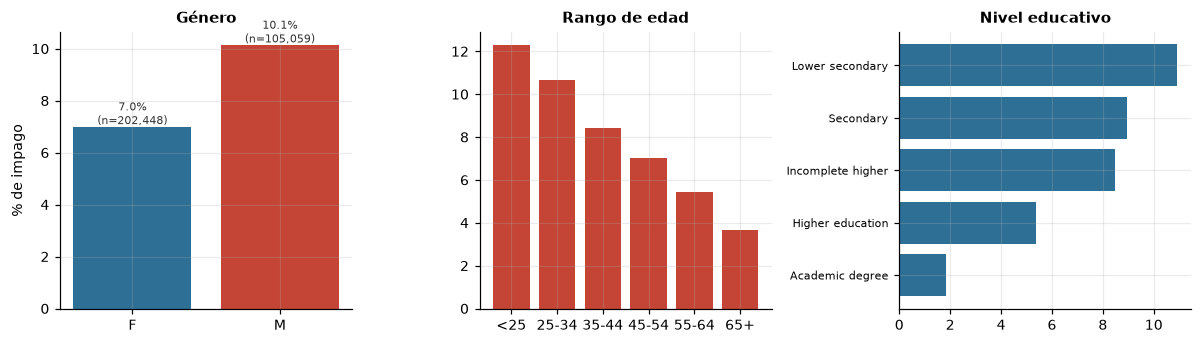

In [11]:
grupos_edad = pd.cut(
    app["edad"],
    [0, 25, 35, 45, 55, 65, 100],
    right=False,
    labels=["<25", "25-34", "35-44", "45-54", "55-64", "65+"],
)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))

genero = app.groupby("CODE_GENDER")[TARGET].agg(["size", "mean"])
genero = genero[genero["size"] > 100].sort_values("mean")
axes[0].bar(genero.index, genero["mean"] * 100, color=[OK, BAD][: len(genero)])
axes[0].set_title("Género")
axes[0].set_ylabel("% de impago")
for i, (n, m) in enumerate(zip(genero["size"], genero["mean"], strict=True)):
    axes[0].text(i, m * 100 + 0.1, f"{m:.1%}\n(n={n:,})", ha="center", fontsize=7, color=INK)

edad = app.groupby(grupos_edad, observed=True)[TARGET].mean()
axes[1].bar(edad.index.astype(str), edad.values * 100, color=BAD)
axes[1].set_title("Rango de edad")

escuela = app.groupby("NAME_EDUCATION_TYPE")[TARGET].mean().sort_values()
axes[2].barh([e.split(" / ")[0] for e in escuela.index], escuela.values * 100, color=OK)
axes[2].set_title("Nivel educativo")
axes[2].tick_params(axis="y", labelsize=7)
save(fig, "06_sesgo")

**Conclusión 6.** Los tres ejes muestran brechas grandes: el impago es **1.45× mayor** en hombres
(10.1 % vs. 7.0 %), **3.4× mayor** en menores de 25 que en mayores de 65 (12.3 % vs. 3.7 %) y cae
con el nivel educativo. Esa es justo la definición de una variable que discrimina y predice a la
vez.

**Decisión tomada aquí, antes de modelar:** `CODE_GENDER` **no entra en el modelo**. Es la
variable más fácil de usar y la más difícil de justificar ante un regulador; en banca, un score
que cambia según el género del solicitante es inaceptable aunque mejore el AUC. `DAYS_BIRTH` sí
entra: la edad es un factor de riesgo aceptado y auditable en crédito, con la salvedad de que hay
que vigilar su peso en la fase 6 y reportar la tasa de aprobación por tramo de edad.
`NAME_EDUCATION_TYPE` se mantiene: es información del solicitante, no un atributo protegido.

Queda registrado en la bitácora como decisión con su coste: se mide el AUC con y sin
`CODE_GENDER` en la fase 4 para saber cuánto se resigna y poder defenderlo con un número.

## Resumen y qué se lleva a la fase 2

In [12]:
resumen = pd.Series(
    {
        "solicitudes": f"{len(app):,}",
        "tasa de impago": f"{app[TARGET].mean():.2%}",
        "ratio 0:1": f"{conteo[0] / conteo[1]:.1f}",
        "columnas crudas": f"{n_columnas_crudas}",
        "columnas con >50 % de nulos": f"{sobre50}",
        "filas con el centinela": f"{es_centinela.sum():,} ({es_centinela.mean():.1%})",
        "corr EXT_SOURCE_1/2/3": " / ".join(f"{app[c].corr(app[TARGET]):+.3f}" for c in ext),
        "tasa impago F / M": f"{genero.loc['F', 'mean']:.2%} / {genero.loc['M', 'mean']:.2%}",
        "tasa impago <25 / 65+": f"{edad.iloc[0]:.2%} / {edad.iloc[-1]:.2%}",
    }
)
print(resumen.to_string())

solicitudes                                     307,511
tasa de impago                                    8.07%
ratio 0:1                                          11.4
columnas crudas                                     122
columnas con >50 % de nulos                          41
filas con el centinela                   55,374 (18.0%)
corr EXT_SOURCE_1/2/3          -0.155 / -0.160 / -0.179
tasa impago F / M                        7.00% / 10.14%
tasa impago <25 / 65+                    12.29% / 3.66%
